# Axis 4 — Trust and verification

**Owner: Member 4 · Branch: `axis-4` · Status: starting notebook, not a completed investigation.**

**Question:** What conditions of trust and verification practices are reported?

**Use for the sponsor:** Inform verification practices to examine alongside tool access.

The proposed sponsor is a DINUM team planning an AI coding-assistant pilot. These French survey respondents are not a sample of DINUM staff. Use the shared population and denominator rules before changing them.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open this notebook from the project root or its notebooks folder.")
sys.path.insert(0, str(ROOT))
from src.data import ensure_data, load_responses, load_schema
from src.population import prepare_population

ensure_data()
population = prepare_population(load_responses())
schema = load_schema()
print("2026 · France · coding as primary job · eligible respondents:", len(population))

2026 · France · coding as primary job · eligible respondents: 628


## 1. Check the fields and the answering population

In [2]:
fields = ['AITrust', 'AIWorkNext', 'AISentiment']
display(schema.loc[schema["column"].isin(fields), ["column", "question", "sub", "transformation"]])
display(pd.DataFrame({"answered": population[fields].notna().sum(),
                      "unanswered": population[fields].isna().sum()}))

,column,question,sub,transformation
105,AISentiment,How would you describe your attitude toward us...,NaN,Original answer
107,AITrust,How much do you trust the output from AI tools...,NaN,Original answer
113,AIWorkNext,When you receive an AI-generated answer for a ...,NaN,"Distinct selections, semicolon-separated"


,answered,unanswered
AITrust,388,240
AIWorkNext,355,273
AISentiment,389,239


## 2. A first descriptive view
This is a starting calculation. Record a factual observation and a separate question after inspecting it.

,answer,respondents,share_pct
0,I trust it when I can easily verify the output,184,47.422680
1,I trust it for low-risk work tasks only,62,15.979381
2,I do not trust it for most work tasks,62,15.979381
3,"I trust it for many tasks, but not important w...",61,15.721649
4,"I trust it for many tasks, including important...",17,4.381443
5,Not sure / I do not use AI tools,2,0.515464


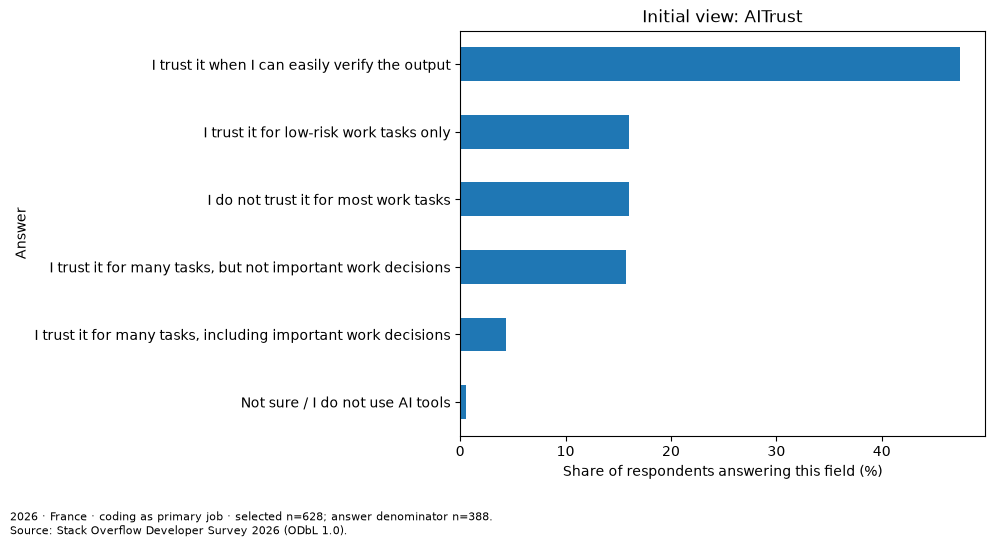

In [3]:
from src.analysis.axis_4 import summarise

column = 'AITrust'
table, answered_n = summarise(population, column)
display(table.head(10))
ax = table.head(10).iloc[::-1].plot.barh(x="answer", y="share_pct", legend=False, figsize=(10, 5))
ax.set(title="Initial view: " + column, xlabel="Share of respondents answering this field (%)", ylabel="Answer")
plt.figtext(.01, -.08, f"2026 · France · coding as primary job · selected n={len(population)}; answer denominator n={answered_n}.\nSource: Stack Overflow Developer Survey 2026 (ODbL 1.0).", fontsize=8)
plt.tight_layout()
plt.show()

## 3. Work still to do — Member 4

1. Explore several useful views and write separate **I notice** / **I wonder** entries.
2. Formulate a testable hypothesis arising from those observations.
3. Explore a trust/checking association among people answering both fields, report the retained sample and consider selection or experience as an alternative explanation. Do not equate trust with accuracy.
4. Explain what the evidence supports, what remains uncertain and what cannot be concluded.
5. Add one useful interaction and one clear view to `views/axis_4.py`, with calculations in `src/analysis/axis_4.py`.
6. Check the shared app and explain the code. Ask the assigned reviewer to read the PR.

Write your own analysis below this plan. The starter calculation is not a finished individual submission.